<a href="https://colab.research.google.com/github/JulianNguyen05/xiangqi-sorting-jetmax/blob/main/training/train_yolo11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BƯỚC 2 — HUẤN LUYỆN YOLO11n NHẬN DIỆN 14 LOẠI QUÂN CỜ TƯỚNG

**Đầu vào:** `merged_v1.zip` (từ notebook `build_dataset.ipynb`) — 6 808 ảnh, 14 lớp
**Đầu ra:** `best.pt` (PyTorch) và `best.onnx` (để build TensorRT trên Jetson Nano của robot JetMax)
**Môi trường:** Google Colab, GPU **Tesla T4** (16 GB), Ultralytics 8.4

### Kết quả chính (trên tập test 664 ảnh, chưa từng dùng khi train)

| Chỉ số | Giá trị | Mục tiêu đề cương |
|---|---|---|
| **mAP@0.5** | **0.968** | ≥ 0.95 ✅ |
| mAP@0.5:0.95 | 0.823 | |
| Precision | 0.986 | |
| Recall | 0.961 | |
| mAP@0.5 khi ảnh xoay 90° / 180° / 270° | 0.968 / 0.968 / 0.968 | không giảm khi xoay ✅ |
| Thời gian suy luận / ảnh (T4, PyTorch) | ~6–8 ms | |
| Kích thước mô hình | 2.6 triệu tham số · 6.5 GFLOPs · 5.5 MB | chạy được trên Jetson Nano |

### Nội dung notebook
1. Vì sao chọn YOLO, vì sao chọn bản YOLO11**n**
2. Phương pháp huấn luyện (transfer learning 2 giai đoạn) và ý nghĩa từng tham số
3. Chuẩn bị dữ liệu, phân tích kích thước quân cờ, minh hoạ augmentation
4. Huấn luyện + theo dõi quá trình train (loss, mAP, learning rate)
5. Đánh giá trên tập test: theo lớp, ma trận nhầm lẫn, ví dụ trực quan
6. So sánh mô hình cũ / mới khi quân cờ bị xoay
7. Xuất ONNX và kiểm tra lại trước khi mang sang robot

---
# 1. Vì sao chọn YOLO?

### 1.1 Đây là bài toán **phát hiện đối tượng** (object detection)
Robot cần biết **quân gì** và **nằm ở đâu** (toạ độ để gắp) cho **nhiều quân trong cùng một ảnh**. Vì vậy:

| Hướng tiếp cận | Đánh giá |
|---|---|
| OpenCV thuần (HoughCircles tìm quân + so khớp mẫu chữ) | Nhạy với ánh sáng, bóng, quân xoay, chữ khắc mờ; phải tinh chỉnh tay nhiều ngưỡng |
| Phân loại ảnh (classification) | Chỉ cho biết *lớp*, không cho *vị trí* → vẫn cần bước tách quân riêng |
| Detector 2 giai đoạn (Faster R-CNN, ...) | Chính xác nhưng nặng, khó đạt thời gian thực trên Jetson Nano |
| **Detector 1 giai đoạn — YOLO** | Một lần chạy mạng ra cả vị trí và lớp, **nhanh**, độ chính xác cao, hệ sinh thái xuất ONNX/TensorRT sẵn có ✅ |

### 1.2 Vì sao YOLO11, và bản **nano (n)**?
- **YOLO11** (Ultralytics) cải tiến kiến trúc so với YOLOv8 (khối **C3k2**, khối chú ý **C2PSA**): theo công bố của Ultralytics trên COCO, YOLO11n đạt **mAP 39.5** với **2.6M tham số**, so với YOLOv8n là 37.3 với 3.2M tham số → **chính xác hơn mà nhẹ hơn**.
- **Thiết bị đích là Jetson Nano** (GPU Maxwell 128 nhân CUDA, RAM 4 GB dùng chung) → chọn bản nhỏ nhất (**n**), đủ chỗ cho cả mô hình lẫn các tiến trình điều khiển robot.
- Bài toán chỉ có 14 lớp, vật thể có hình dạng đơn giản (đĩa tròn) → mô hình nano là đủ, như kết quả mAP@0.5 = 0.968 cho thấy.
- Ultralytics hỗ trợ **transfer learning** từ trọng số COCO, augmentation có sẵn, và **xuất ONNX → TensorRT** để chạy FP16 trên Jetson.

Biểu đồ bên dưới so sánh theo số liệu công bố của Ultralytics (COCO val2017, ảnh 640).

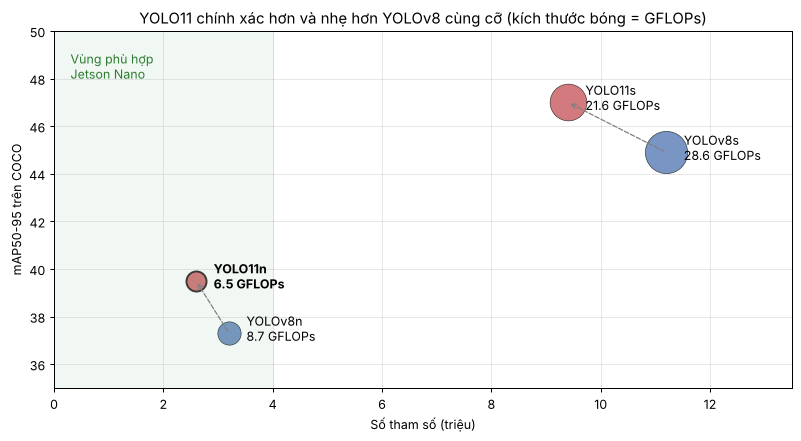

In [ ]:
# ── Biểu đồ so sánh YOLOv8 và YOLO11 (số liệu công bố của Ultralytics trên COCO, ảnh 640)
#    Nguồn: https://docs.ultralytics.com/compare/yolo11-vs-yolov8
import matplotlib.pyplot as plt

models = {  # tên: (triệu tham số, mAP50-95 COCO, GFLOPs)
    'YOLOv8n': (3.2, 37.3, 8.7), 'YOLO11n': (2.6, 39.5, 6.5),
    'YOLOv8s': (11.2, 44.9, 28.6), 'YOLO11s': (9.4, 47.0, 21.6),
}
fig, ax = plt.subplots(figsize=(9, 5))
for name, (p, m, fl) in models.items():
    is11 = name.startswith('YOLO11')
    ax.scatter(p, m, s=fl * 40, color='#C44E52' if is11 else '#4C72B0', alpha=0.75,
               edgecolor='black', lw=1.5 if name == 'YOLO11n' else 0.5)
    ax.annotate(f'{name}\n{fl} GFLOPs', (p, m), textcoords='offset points', xytext=(14, -6), fontsize=10,
                fontweight='bold' if name == 'YOLO11n' else 'normal')
for a, b in [('YOLOv8n', 'YOLO11n'), ('YOLOv8s', 'YOLO11s')]:
    ax.annotate('', xy=models[b][:2], xytext=models[a][:2], arrowprops=dict(arrowstyle='->', color='gray', ls='--'))
ax.axvspan(0, 4, color='#55A868', alpha=0.08)
ax.text(0.3, 48, 'Vùng phù hợp\nJetson Nano', color='#2E7D32', fontsize=10)
ax.set_xlim(0, 13.5); ax.set_ylim(35, 50)
ax.set_xlabel('Số tham số (triệu)'); ax.set_ylabel('mAP50-95 trên COCO')
ax.set_title('YOLO11 chính xác hơn và nhẹ hơn YOLOv8 cùng cỡ (kích thước bóng = GFLOPs)')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

---
# 2. Phương pháp huấn luyện

### 2.1 Transfer learning 2 giai đoạn
Không train từ con số 0 mà **kế thừa** trọng số đã học:

| Giai đoạn | Xuất phát | Dữ liệu / mục tiêu | Tham số chính | Kết quả |
|---|---|---|---|---|
| 0 | — | COCO (80 lớp vật thể thường ngày) — do Ultralytics train sẵn | — | `yolo11n.pt`: đã biết nhận cạnh, góc, hình khối |
| 1 | `yolo11n.pt` | `merged_v1` — quân cờ trên băng chuyền, lệch góc nhẹ | 100 epoch, `degrees=10`, `fliplr=0` | `yolo11n_640/best.pt` |
| **2** (notebook này) | `yolo11n_640/best.pt` | Quân trong **khay, nằm xoay bất kỳ 0–360°** | 60 epoch, **`degrees=180`**, `flipud=0`, AdamW `lr0=0.001` | `yolo11n_640_rot/best.pt` |

**Vì sao cần giai đoạn 2?** Yêu cầu bài toán đổi từ băng chuyền (quân gần như thẳng hướng) sang gắp quân từ khay (quân xoay mọi hướng). Mô hình giai đoạn 1 tụt mạnh khi ảnh xoay 90° (mAP@0.5 từ 0.96 xuống 0.76, xem phần 6). Thay vì train lại từ đầu, **fine-tune** từ mô hình giai đoạn 1 với learning rate nhỏ: giữ được những gì đã học về chữ/màu quân, chỉ học thêm việc nhận quân ở mọi góc → tốn ít epoch hơn.

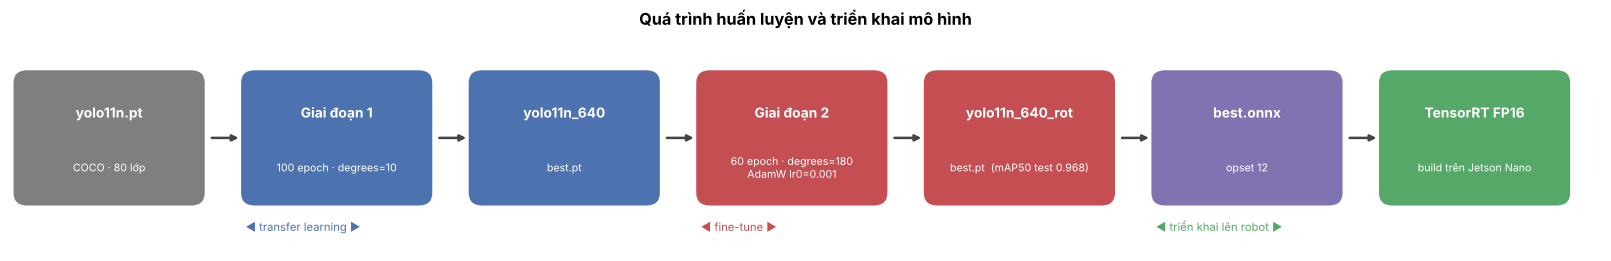

In [ ]:
# ── Sơ đồ quá trình huấn luyện và triển khai (chỉ để minh hoạ)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

nodes = [
    ('yolo11n.pt', 'COCO · 80 lớp', '#7F7F7F'),
    ('Giai đoạn 1', '100 epoch · degrees=10', '#4C72B0'),
    ('yolo11n_640', 'best.pt', '#4C72B0'),
    ('Giai đoạn 2', '60 epoch · degrees=180\nAdamW lr0=0.001', '#C44E52'),
    ('yolo11n_640_rot', 'best.pt  (mAP50 test 0.968)', '#C44E52'),
    ('best.onnx', 'opset 12', '#8172B2'),
    ('TensorRT FP16', 'build trên Jetson Nano', '#55A868'),
]
fig, ax = plt.subplots(figsize=(18, 3))
ax.set_xlim(0, len(nodes) * 2.5); ax.set_ylim(0, 2.6); ax.axis('off')
for i, (t, s, c) in enumerate(nodes):
    x = i * 2.5 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.6), 2.0, 1.5, boxstyle='round,pad=0.05,rounding_size=0.15', fc=c, ec='none'))
    ax.text(x + 1.0, 1.65, t, ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    ax.text(x + 1.0, 1.0, s, ha='center', va='center', color='white', fontsize=8.5)
    if i < len(nodes) - 1:
        ax.annotate('', xy=(x + 2.45, 1.35), xytext=(x + 2.1, 1.35), arrowprops=dict(arrowstyle='-|>', lw=2, color='#444'))
ax.text(0.1 + 2.5 * 1, 0.25, '◄ transfer learning ►', fontsize=9, color='#4C72B0')
ax.text(0.1 + 2.5 * 3, 0.25, '◄ fine-tune ►', fontsize=9, color='#C44E52')
ax.text(0.1 + 2.5 * 5, 0.25, '◄ triển khai lên robot ►', fontsize=9, color='#55A868')
ax.set_title('Quá trình huấn luyện và triển khai mô hình', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

### 2.2 Các tham số huấn luyện (giai đoạn 2) và lý do chọn

**Tham số đặt tay** (⚠ quan trọng nhất):

| Tham số | Giá trị | Ý nghĩa | Lý do chọn |
|---|---|---|---|
| `imgsz` | 640 | Ảnh được resize (giữ tỷ lệ, đệm viền) về 640×640 | Kích thước gốc của trọng số pretrained; đủ chi tiết để đọc chữ (xem phân tích kích thước quân ở mục 3) mà vẫn nhanh trên Jetson |
| `epochs` | 60 | Số lần duyệt hết tập train | Fine-tune từ mô hình đã tốt → ít hơn giai đoạn 1 (100) |
| `batch` | 32 | Số ảnh mỗi bước cập nhật | Vừa bộ nhớ T4 (dùng ~6.3 GB); 5 469 / 32 = **171 bước/epoch** |
| `optimizer` | AdamW | Thuật toán tối ưu | Hội tụ ổn định khi fine-tune với LR nhỏ |
| `lr0` | 0.001 | Learning rate ban đầu | Nhỏ để **không phá** đặc trưng đã học ở giai đoạn 1 |
| `degrees` | **180** | Xoay ảnh ngẫu nhiên trong [−180°, +180°] | Quân trong khay nằm theo mọi hướng |
| `fliplr`, `flipud` | **0** | Tắt lật ngang / lật dọc | Lật biến chữ Hán thành **ảnh gương** — chữ không có thật → dạy sai mô hình (xem minh hoạ mục 3) |
| `patience` | 20 | Dừng sớm nếu 20 epoch liền không cải thiện | Tránh lãng phí GPU khi đã hội tụ |
| `close_mosaic` | 10 | Tắt mosaic ở 10 epoch cuối | Cho mô hình làm quen lại với ảnh "thật" (không ghép) trước khi kết thúc |
| `save_period` | 10 | Lưu checkpoint mỗi 10 epoch | Colab có thể ngắt giữa chừng |

**Tham số để mặc định** (đọc từ log huấn luyện):

| Nhóm | Tham số | Giá trị | Ý nghĩa |
|---|---|---|---|
| Learning rate | `lrf` · `warmup_epochs` · `momentum` · `weight_decay` | 0.01 · 3 · 0.937 · 0.0005 | LR giảm tuyến tính từ `lr0` về `lr0×lrf`; 3 epoch đầu "khởi động" LR tăng dần |
| Augment màu | `hsv_h` · `hsv_s` · `hsv_v` | 0.015 · 0.7 · 0.4 | Đổi sắc độ / độ bão hoà / độ sáng → chịu được ánh sáng khác nhau |
| Augment hình | `translate` · `scale` · `mosaic` · `erasing` | 0.1 · 0.5 · 1.0 · 0.4 | Dịch, phóng to/thu nhỏ ±50%, ghép 4 ảnh, xoá ngẫu nhiên một vùng |
| Trọng số loss | `box` · `cls` · `dfl` | 7.5 · 0.5 · 1.5 | Mức ưu tiên giữa vị trí box, phân lớp và độ sắc của biên box |
| Khác | `amp` · `nbs` | True · 64 | Mixed precision FP16 (nhanh hơn trên T4); gom gradient 2 batch = batch danh nghĩa 64 |

> Ghi chú: khi xoay ảnh, Ultralytics tính box mới là hình chữ nhật bao 4 góc đã xoay, nên ở góc 45° box hơi rộng hơn quân thật. Vì quân cờ hình tròn nên ảnh hưởng nhỏ, nhưng đây có thể là một lý do mAP@0.5:0.95 (đòi hỏi box rất khít) thấp hơn mAP@0.5.

### 2.3 Hàm mất mát (loss) và các chỉ số đánh giá

**Loss** mà YOLO11 tối ưu: $\;L = 7.5\cdot L_{box} + 0.5\cdot L_{cls} + 1.5\cdot L_{dfl}$

| Thành phần | Đo cái gì | Cách tính |
|---|---|---|
| `box_loss` | Box dự đoán lệch box thật bao nhiêu | $1 - \text{CIoU}$ (IoU có phạt khoảng cách tâm và tỷ lệ cạnh) |
| `cls_loss` | Phân lớp sai bao nhiêu | Binary cross-entropy trên 14 lớp |
| `dfl_loss` | Độ "sắc" của biên box | Distribution Focal Loss: mỗi cạnh box được dự đoán dưới dạng phân phối xác suất |

**Chỉ số đánh giá:**
- **IoU** $= \dfrac{|A\cap B|}{|A\cup B|}$ — độ trùng giữa box dự đoán và box thật. Một dự đoán là **đúng (TP)** khi đúng lớp và IoU ≥ ngưỡng.
- **Precision** $= \dfrac{TP}{TP+FP}$ — trong các quân mô hình báo, bao nhiêu % là đúng → cao nghĩa là **ít báo nhầm** (robot ít gắp sai quân).
- **Recall** $= \dfrac{TP}{TP+FN}$ — trong các quân có thật, mô hình tìm được bao nhiêu % → cao nghĩa là **ít bỏ sót**.
- **AP** của một lớp = diện tích dưới đường Precision–Recall. **mAP@0.5** = trung bình AP của 14 lớp ở ngưỡng IoU 0.5. **mAP@0.5:0.95** = trung bình thêm trên 10 ngưỡng IoU 0.50, 0.55, …, 0.95 (khắt khe hơn về độ khít của box).
- `best.pt` là epoch có **fitness** cao nhất trên tập val, với fitness $= 0.1\cdot\text{mAP@0.5} + 0.9\cdot\text{mAP@0.5:0.95}$ (mặc định của Ultralytics).

---
# 3. Chuẩn bị môi trường và dữ liệu

## Chuẩn bị môi trường
Kiểm tra GPU, mount Drive và cài ultralytics.

In [8]:
import torch
# ⚠ Phải có GPU (Runtime → Change runtime type → T4). Train trên CPU sẽ mất nhiều ngày.
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'KHÔNG CÓ GPU - đổi runtime sang T4')

from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Kiểm tra hai file cần có trên Drive: dataset hợp nhất và `best.pt` của **giai đoạn 1** (điểm xuất phát của lần fine-tune này).

In [9]:
import os
BASE = '/content/drive/MyDrive/datn'
OLD_RUN = f'{BASE}/runs/yolo11n_640'          # lần train trước (giai đoạn 1, degrees=10)
for p in [
    f'{BASE}/merged/merged_v1.zip',           # dataset từ build_dataset.ipynb
    f'{OLD_RUN}/weights/best.pt',             # trọng số xuất phát cho fine-tune
]:
    print(os.path.exists(p), p)

True /content/drive/MyDrive/datn/merged/merged_v1.zip
True /content/drive/MyDrive/datn/runs/yolo11n_640/weights/best.pt


## Giải nén dataset hợp nhất
Copy merged_v1.zip từ Drive về máy Colab (đọc nhanh hơn đọc trực tiếp từ Drive) và kiểm tra số ảnh/nhãn mỗi tập.

In [10]:
import os, shutil

BASE = '/content/drive/MyDrive/datn'
MERGED = '/content/merged'

# Giải nén về ổ cục bộ của Colab: đọc ảnh nhanh hơn nhiều so với đọc trực tiếp từ Drive
if not os.path.isdir(f'{MERGED}/train'):
    shutil.unpack_archive(f'{BASE}/merged/merged_v1.zip', MERGED)

for s in ['train', 'val', 'test']:
    print(s, len(os.listdir(f'{MERGED}/{s}/images')), 'ảnh |', len(os.listdir(f'{MERGED}/{s}/labels')), 'nhãn')

print(open(f'{MERGED}/data.yaml').read())

train 5469 ảnh | 5469 nhãn
val 675 ảnh | 675 nhãn
test 664 ảnh | 664 nhãn
path: /content/merged
train: train/images
val: val/images
test: test/images
nc: 14
names:
- black_advisor
- black_bishop
- black_cannon
- black_king
- black_knight
- black_pawn
- black_rook
- red_advisor
- red_bishop
- red_cannon
- red_king
- red_knight
- red_pawn
- red_rook



## Kiểm tra nhãn trước khi huấn luyện
Đảm bảo mỗi ảnh đều có file nhãn tương ứng và mọi class id nằm trong khoảng 0-13. Nhãn sai class id sẽ làm quá trình train báo lỗi hoặc cho kết quả sai.

In [11]:
import glob

bad = 0
for s in ['train', 'val', 'test']:
    # Ảnh và nhãn phải khớp 1-1
    imgs = {os.path.splitext(f)[0] for f in os.listdir(f'{MERGED}/{s}/images')}
    lbls = {os.path.splitext(f)[0] for f in os.listdir(f'{MERGED}/{s}/labels')}
    print(s, '| ảnh thiếu nhãn:', len(imgs - lbls), '| nhãn thiếu ảnh:', len(lbls - imgs))
    # Class id phải nằm trong 0..13
    for p in glob.glob(f'{MERGED}/{s}/labels/*.txt'):
        for line in open(p):
            parts = line.split()
            if parts and not (0 <= int(parts[0]) <= 13):
                bad += 1
print('Dòng nhãn có class id sai:', bad)

train | ảnh thiếu nhãn: 0 | nhãn thiếu ảnh: 0
val | ảnh thiếu nhãn: 0 | nhãn thiếu ảnh: 0
test | ảnh thiếu nhãn: 0 | nhãn thiếu ảnh: 0
Dòng nhãn có class id sai: 0


### 📊 Phân tích kích thước quân cờ → cơ sở chọn `imgsz = 640`
YOLO11 phát hiện vật ở 3 tỉ lệ: lưới 80×80 (stride 8, vật nhỏ), 40×40 (stride 16) và 20×20 (stride 32, vật lớn). Ô dưới tính cạnh của mỗi quân cờ **sau khi ảnh được thu về 640** để xem quân có đủ lớn không: nếu phần lớn quân < 16 px thì chữ Hán sẽ quá mờ, cần tăng `imgsz`.

In [ ]:
import random, numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMGSZ_CHECK = 640
img_of = {os.path.splitext(f)[0]: f for f in os.listdir(f'{MERGED}/train/images')}
lbl_files = glob.glob(f'{MERGED}/train/labels/*.txt')
sample = random.Random(0).sample(lbl_files, min(2000, len(lbl_files)))   # lấy mẫu cho nhanh

sides, per_img = [], []
for lf in sample:
    stem = os.path.splitext(os.path.basename(lf))[0]
    with Image.open(f'{MERGED}/train/images/{img_of[stem]}') as im:   # chỉ đọc header, rất nhanh
        W, H = im.size
    scale = IMGSZ_CHECK / max(W, H)                                     # tỷ lệ thu nhỏ khi letterbox
    rows = [l.split() for l in open(lf) if l.strip()]
    per_img.append(len(rows))
    for r in rows:
        w, h = float(r[3]) * W * scale, float(r[4]) * H * scale
        sides.append(np.sqrt(w * h))
sides = np.array(sides)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(sides, bins=60, color='#4C72B0')
for s, lab in [(8, 'stride 8'), (16, 'stride 16'), (32, 'stride 32')]:
    axes[0].axvline(s, color='#C44E52', ls='--', lw=1); axes[0].text(s + 0.8, axes[0].get_ylim()[1] * 0.97, lab, color='#C44E52', fontsize=9, rotation=90, va='top')
axes[0].axvline(np.median(sides), color='black', lw=2)
axes[0].text(np.median(sides) + 2, axes[0].get_ylim()[1] * 0.7, f'trung vị {np.median(sides):.0f} px', fontsize=10)
axes[0].set_xlabel(f'Cạnh quân cờ (pixel) sau khi thu về {IMGSZ_CHECK}'); axes[0].set_ylabel('Số box')
axes[0].set_title('Kích thước quân cờ khi đưa vào mô hình')
axes[1].hist(per_img, bins=range(0, max(per_img) + 2), color='#55A868')
axes[1].set_xlabel('Số quân trong một ảnh'); axes[1].set_ylabel('Số ảnh'); axes[1].set_title('Mật độ quân cờ mỗi ảnh')
plt.tight_layout(); plt.show()

print(f'{len(sides):,} box từ {len(sample):,} ảnh | cạnh trung vị = {np.median(sides):.1f} px | '
      f'< 16 px: {(sides < 16).mean() * 100:.1f}% | < 24 px: {(sides < 24).mean() * 100:.1f}%')

### 🖼 Minh hoạ augmentation: vì sao **xoay** được nhưng **lật** thì không
Hàng trên: một quân cờ cắt từ tập train qua các phép biến đổi. Xoay chỉ làm quân nằm nghiêng — **chữ vẫn là chữ thật** (giống quân nằm trong khay). Lật ngang/dọc tạo ra **chữ ngược gương**, không bao giờ xuất hiện ngoài thực tế → nếu dùng sẽ dạy mô hình sai.
Hàng dưới: augmentation màu HSV trên ảnh đầy đủ — giúp mô hình chịu được ánh sáng khác nhau.

In [ ]:
import cv2

def rotate(img, deg):
    # Xoay quanh tâm, phần trống tô màu xám 114 giống Ultralytics
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderValue=(114, 114, 114))

def hsv_jitter(img, hgain=0.015, sgain=0.7, vgain=0.4, seed=0):
    # Tái hiện augment HSV của Ultralytics với hệ số ngẫu nhiên
    r = np.random.RandomState(seed).uniform(-1, 1, 3) * [hgain, sgain, vgain] + 1
    hue, sat, val = cv2.split(cv2.cvtColor(img, cv2.COLOR_RGB2HSV))
    x = np.arange(256, dtype=r.dtype)
    lut_h = ((x * r[0]) % 180).astype(np.uint8)
    lut_s = np.clip(x * r[1], 0, 255).astype(np.uint8); lut_v = np.clip(x * r[2], 0, 255).astype(np.uint8)
    out = cv2.merge((cv2.LUT(hue, lut_h), cv2.LUT(sat, lut_s), cv2.LUT(val, lut_v)))
    return cv2.cvtColor(out, cv2.COLOR_HSV2RGB)

# Tìm quân cờ có kích thước lớn nhất trong 300 ảnh train ngẫu nhiên để thấy rõ chữ
names = ['black_advisor', 'black_bishop', 'black_cannon', 'black_king', 'black_knight', 'black_pawn', 'black_rook',
         'red_advisor', 'red_bishop', 'red_cannon', 'red_king', 'red_knight', 'red_pawn', 'red_rook']
best_box = None
for lf in random.Random(1).sample(lbl_files, min(300, len(lbl_files))):
    stem = os.path.splitext(os.path.basename(lf))[0]
    with Image.open(f'{MERGED}/train/images/{img_of[stem]}') as im:
        W, H = im.size
    for r in (l.split() for l in open(lf) if l.strip()):
        c, x, y, w, h = int(r[0]), *map(float, r[1:])
        if best_box is None or w * W * h * H > best_box[0]:
            best_box = (w * W * h * H, stem, c, x, y, w, h)
_, stem, c, x, y, w, h = best_box
full = cv2.cvtColor(cv2.imread(f'{MERGED}/train/images/{img_of[stem]}'), cv2.COLOR_BGR2RGB)
H, W = full.shape[:2]
side = int(max(w * W, h * H) * 1.4)
cx, cy = int(x * W), int(y * H)
piece = full[max(0, cy - side // 2): cy + side // 2, max(0, cx - side // 2): cx + side // 2]

variants = [('Gốc', piece, True), ('Xoay 45°', rotate(piece, 45), True), ('Xoay 90°', rotate(piece, 90), True),
            ('Xoay 180°', rotate(piece, 180), True), ('Lật ngang (fliplr)', piece[:, ::-1], False),
            ('Lật dọc (flipud)', piece[::-1], False)]
fig, axes = plt.subplots(2, 6, figsize=(20, 7.5))
for ax, (t, im, ok) in zip(axes[0], variants):
    ax.imshow(im); ax.axis('off')
    ax.set_title(('✓ ' if ok else '✗ ') + t + ('' if ok else '\nchữ bị ngược gương'),
                 color='#2E7D32' if ok else '#C62828', fontsize=11, fontweight='bold')
axes[0][0].set_title(f'✓ Gốc ({names[c]})', color='#2E7D32', fontsize=11, fontweight='bold')
hsv_imgs = [('Ảnh gốc', full)] + [(f'HSV ngẫu nhiên #{k}', hsv_jitter(full, seed=k)) for k in range(1, 4)] + \
           [('Xoay 30° + HSV', rotate(hsv_jitter(full, seed=5), 30)), ('Xoay 135°', rotate(full, 135))]
for ax, (t, im) in zip(axes[1], hsv_imgs):
    ax.imshow(im); ax.set_title(t, fontsize=10); ax.axis('off')
fig.suptitle('Augmentation dùng trong giai đoạn 2 (fliplr = flipud = 0, degrees = 180)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
# 4. Huấn luyện

## Khai báo tham số huấn luyện
**Lần train thứ 2 (v2):** bài toán đổi từ băng chuyền sang *gắp quân từ khay lên bàn cờ*. Trong khay quân nằm xoay **bất kỳ 0–360°**, nên phải tăng xoay ảnh khi train từ 10° lên 180°.

Không train lại từ đầu mà **fine-tune từ `best.pt` của lần trước** (đã học tốt hình dạng quân, chỉ cần học thêm quân xoay), nên ít epoch hơn. Kết quả lưu vào run mới `yolo11n_640_rot`, không ghi đè run cũ để còn so sánh.

In [12]:
from ultralytics import YOLO

DATA     = f'{MERGED}/data.yaml'
PROJECT  = f'{BASE}/runs'                              # kết quả lưu trên Drive
NAME     = 'yolo11n_640_rot'                           # run mới, KHÔNG ghi đè run cũ để còn so sánh
OLD_BEST = f'{PROJECT}/yolo11n_640/weights/best.pt'    # trọng số giai đoạn 1 = điểm xuất phát

EPOCHS  = 60
IMGSZ   = 640
BATCH   = 32

# Nếu run này đã train xong (đã có best.pt trên Drive) thì bỏ qua ô train,
# để có thể "Run all" lại notebook khi trình bày mà không phải train lại 1.7 giờ.
RUN_TRAIN = not os.path.exists(f'{PROJECT}/{NAME}/weights/best.pt')
print('Sẽ train:', RUN_TRAIN)

## Nạp mô hình từ lần train trước
Dùng `best.pt` của run `yolo11n_640` (đã huấn luyện trên dataset hợp nhất 14 lớp) làm điểm xuất phát.

In [13]:
model = YOLO(OLD_BEST)   # nạp kiến trúc + trọng số của giai đoạn 1
print(model.names)       # ⚠ phải đúng 14 lớp, đúng thứ tự id như data.yaml

{0: 'black_advisor', 1: 'black_bishop', 2: 'black_cannon', 3: 'black_king', 4: 'black_knight', 5: 'black_pawn', 6: 'black_rook', 7: 'red_advisor', 8: 'red_bishop', 9: 'red_cannon', 10: 'red_king', 11: 'red_knight', 12: 'red_pawn', 13: 'red_rook'}


## Huấn luyện mô hình (fine-tune)
Thay đổi so với lần 1:
- `degrees=180`: **xoay ngẫu nhiên tới ±180°**, vì quân trong khay nằm theo mọi hướng (lần 1 chỉ 10°).
- `fliplr=0.0`, `flipud=0.0`: vẫn tắt lật ảnh, vì lật làm chữ Hán bị đảo ngược (thành ảnh gương), gây nhầm lớp. Xoay 180° thì không đảo chữ nên an toàn.
- `optimizer='AdamW'`, `lr0=0.001`: learning rate nhỏ, phù hợp fine-tune, tránh làm hỏng những gì model đã học.
- `epochs=60`, `patience=20`: ít hơn lần 1 vì xuất phát từ model đã tốt.

Giữ nguyên: `save_period=10`, `close_mosaic=10`. Thời gian ước tính khoảng 40–60 phút trên T4.

In [14]:
if RUN_TRAIN:
    results = model.train(
        data=DATA,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        patience=20,           # dừng sớm nếu 20 epoch không cải thiện
        project=PROJECT,
        name=NAME,
        exist_ok=True,
        save_period=10,        # lưu checkpoint mỗi 10 epoch (phòng Colab ngắt)
        workers=2,
        optimizer='AdamW',     # ⚠ fine-tune: AdamW + learning rate nhỏ
        lr0=0.001,
        fliplr=0.0,            # ⚠ KHÔNG lật: lật làm chữ Hán thành ảnh gương
        flipud=0.0,
        degrees=180,           # ⚠ xoay ngẫu nhiên ±180°: quân trong khay nằm mọi hướng
        close_mosaic=10,       # tắt mosaic ở 10 epoch cuối
        plots=True,            # lưu biểu đồ + ảnh batch để báo cáo
    )
else:
    print('Đã có kết quả train trên Drive -> bỏ qua. Xoá thư mục run hoặc đặt RUN_TRAIN = True để train lại.')

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/merged/data.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/datn/runs/yolo11n_640/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_640_ro

### Đọc log huấn luyện
Mỗi epoch in 2 dòng:

| Cột | Ý nghĩa |
|---|---|
| `Epoch` | epoch hiện tại / tổng số |
| `GPU_mem` | bộ nhớ GPU đang dùng (~6.25 GB trên 15 GB của T4) |
| `box_loss`, `cls_loss`, `dfl_loss` | 3 thành phần loss trên tập train (càng nhỏ càng tốt) |
| `Instances` | số quân cờ trong batch cuối của epoch |
| `171/171` | 171 bước = ⌈5 469 ảnh / 32⌉; ~1 phút 18 giây mỗi epoch |
| Dòng `all ... P R mAP50 mAP50-95` | đánh giá trên tập **val** (675 ảnh, 10 788 quân) sau mỗi epoch |

**Kết quả:** chạy đủ 60 epoch trong **1.7 giờ** (không dừng sớm). Epoch cuối: P = 0.992, R = 0.962, mAP50 = 0.968, mAP50-95 = 0.830 trên val. Phần cuối log là bảng đánh giá `best.pt` theo từng lớp.

## Tiếp tục huấn luyện nếu bị ngắt giữa chừng
Chỉ chạy ô này khi Colab ngắt kết nối lúc đang train. Chạy lại phần chuẩn bị môi trường, giải nén dataset và ô khai báo tham số, **bỏ qua** ô nạp mô hình và ô train, rồi chạy ô dưới để train tiếp từ `last.pt`.

In [15]:
# Bỏ dấu # ở 2 dòng dưới để train tiếp từ checkpoint gần nhất (last.pt) khi Colab bị ngắt
# model = YOLO(f'{PROJECT}/{NAME}/weights/last.pt')
# model.train(resume=True)

---
# 5. Phân tích quá trình huấn luyện

## Xem kết quả huấn luyện
Đọc `results.csv` và vẽ đường loss cùng mAP theo từng epoch. Loss giảm đều và mAP tăng rồi đi ngang là dấu hiệu huấn luyện tốt. Nếu loss val tăng trong khi loss train giảm thì mô hình đang overfit.

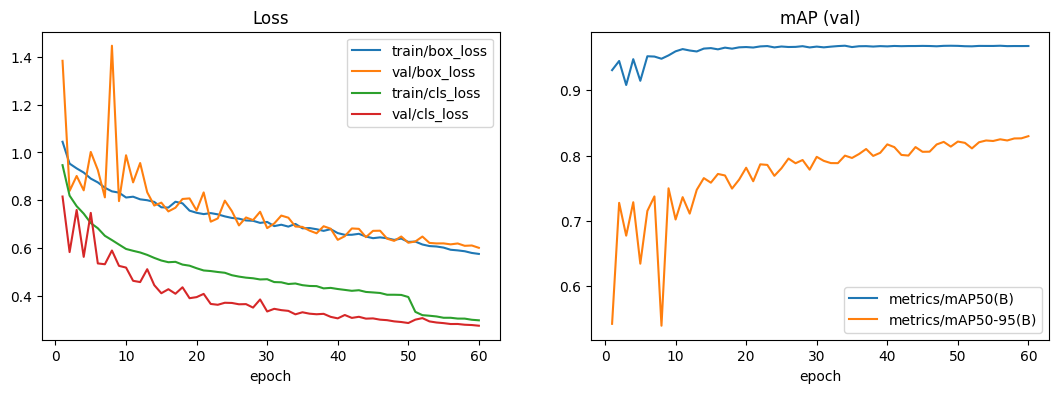

    epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
57     58               0.99111            0.96178           0.96770   
58     59               0.99330            0.96030           0.96767   
59     60               0.99240            0.96193           0.96774   

    metrics/mAP50-95(B)  
57              0.82618  
58              0.82636  
59              0.82969  


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# results.csv: Ultralytics ghi 1 dòng / epoch gồm loss, metrics và learning rate
df = pd.read_csv(f'{PROJECT}/{NAME}/results.csv')
df.columns = df.columns.str.strip()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for c in ['train/box_loss', 'val/box_loss', 'train/cls_loss', 'val/cls_loss']:
    ax[0].plot(df['epoch'], df[c], label=c)
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()

for c in ['metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
    ax[1].plot(df['epoch'], df[c], label=c)
ax[1].set_title('mAP (val)'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.show()

print(df[['epoch', 'metrics/precision(B)', 'metrics/recall(B)',
          'metrics/mAP50(B)', 'metrics/mAP50-95(B)']].tail(3))

### 📈 Bảng điều khiển chi tiết của quá trình huấn luyện
Sáu biểu đồ: 3 thành phần loss (train vs val), precision/recall, mAP so với mục tiêu 0.95, và learning rate theo epoch.
- **Vùng tô xám** = 10 epoch cuối đã tắt mosaic (`close_mosaic=10`): loss train thường giảm rõ ở đây vì ảnh "dễ" hơn.
- **Đường đứt nét dọc** = epoch được chọn làm `best.pt`.
- **Cách đọc:** loss train và val cùng giảm, không có chỗ val tăng ngược trở lại → **không overfit**.

In [ ]:
import numpy as np

res = pd.read_csv(f'{PROJECT}/{NAME}/results.csv'); res.columns = res.columns.str.strip()
fitness = 0.1 * res['metrics/mAP50(B)'] + 0.9 * res['metrics/mAP50-95(B)']    # tiêu chí chọn best.pt
best_ep = int(res.loc[fitness.idxmax(), 'epoch'])
E = int(res['epoch'].max())

def deco(ax, title):
    ax.axvspan(max(E - 10, 0) + 0.5, E + 0.5, color='gray', alpha=0.12)        # vùng tắt mosaic
    ax.axvline(best_ep, color='black', ls='--', lw=1)
    ax.set_title(title); ax.set_xlabel('epoch'); ax.grid(alpha=0.3)

fig, axes = plt.subplots(2, 3, figsize=(19, 9.5))
for ax, part in zip(axes[0], ['box', 'cls', 'dfl']):
    ax.plot(res['epoch'], res[f'train/{part}_loss'], color='#4C72B0', lw=2, label='train')
    ax.plot(res['epoch'], res[f'val/{part}_loss'], color='#DD8452', lw=2, label='val')
    deco(ax, f'{part}_loss'); ax.legend()

ax = axes[1][0]
ax.plot(res['epoch'], res['metrics/precision(B)'], color='#55A868', lw=2, label='Precision')
ax.plot(res['epoch'], res['metrics/recall(B)'], color='#8172B2', lw=2, label='Recall')
deco(ax, 'Precision / Recall (val)'); ax.legend()

ax = axes[1][1]
ax.plot(res['epoch'], res['metrics/mAP50(B)'], color='#C44E52', lw=2, label='mAP@0.5')
ax.plot(res['epoch'], res['metrics/mAP50-95(B)'], color='#937860', lw=2, label='mAP@0.5:0.95')
ax.axhline(0.95, color='#C44E52', ls=':', lw=1.5); ax.text(1, 0.952, 'mục tiêu 0.95', color='#C44E52', fontsize=9)
deco(ax, 'mAP (val)'); ax.legend(loc='lower right')

ax = axes[1][2]
for k, col in [('lr/pg0', '#4C72B0'), ('lr/pg2', '#DD8452')]:
    if k in res:
        ax.plot(res['epoch'], res[k], lw=2, color=col, label=k)
deco(ax, 'Learning rate'); ax.legend(); ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

fig.suptitle(f'Quá trình fine-tune {NAME} — best.pt tại epoch {best_ep}  (vùng xám: tắt mosaic)',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

b = res.loc[res.epoch == best_ep].iloc[0]
print(f"best.pt @ epoch {best_ep}: P={b['metrics/precision(B)']:.3f} R={b['metrics/recall(B)']:.3f} "
      f"mAP50={b['metrics/mAP50(B)']:.3f} mAP50-95={b['metrics/mAP50-95(B)']:.3f}")
print(f"Tổng thời gian: {res['time'].max() / 3600:.2f} giờ" if 'time' in res else '')

### 📈 Toàn bộ hành trình: giai đoạn 1 → giai đoạn 2
Nối `results.csv` của hai lần train trên cùng một trục epoch. Lưu ý: điểm val ở đây được đo trên ảnh **không xoay**, nên đồ thị chủ yếu cho thấy giai đoạn 2 **giữ được** độ chính xác cũ; lợi ích khi xoay được chứng minh ở mục 6. Bảng bên dưới so sánh tham số của hai lần train (đọc từ `args.yaml` mà Ultralytics lưu cùng mỗi run).

In [ ]:
import yaml

old_csv = f'{OLD_RUN}/results.csv'
if os.path.exists(old_csv):
    r1 = pd.read_csv(old_csv); r1.columns = r1.columns.str.strip()
    off = int(r1['epoch'].max())
    fig, ax = plt.subplots(figsize=(15, 4.5))
    for col, c, lab in [('metrics/mAP50(B)', '#C44E52', 'mAP@0.5'), ('metrics/mAP50-95(B)', '#4C72B0', 'mAP@0.5:0.95')]:
        ax.plot(r1['epoch'], r1[col], color=c, lw=2, label=f'{lab} — GĐ1')
        ax.plot(res['epoch'] + off, res[col], color=c, lw=2, ls='--', label=f'{lab} — GĐ2')
    ax.axvline(off + 0.5, color='black', lw=1.5)
    ax.text(off * 0.5, ax.get_ylim()[0] + 0.02, 'Giai đoạn 1: degrees=10', ha='center', fontsize=11)
    ax.text(off + res['epoch'].max() / 2, ax.get_ylim()[0] + 0.02, 'Giai đoạn 2:\ndegrees=180', ha='center', fontsize=11)
    ax.set_xlabel('epoch (cộng dồn)'); ax.set_ylabel('mAP (val, ảnh không xoay)'); ax.grid(alpha=0.3)
    ax.set_title('mAP trên tập val qua hai giai đoạn huấn luyện'); ax.legend(ncol=2, loc='center right')
    plt.tight_layout(); plt.show()
else:
    print('Không thấy', old_csv)

# So sánh tham số của 2 lần train
KEYS = ['model', 'epochs', 'imgsz', 'batch', 'optimizer', 'lr0', 'lrf', 'degrees', 'fliplr', 'flipud',
        'mosaic', 'close_mosaic', 'hsv_h', 'hsv_s', 'hsv_v', 'scale', 'translate', 'patience']
args = {}
for tag, d in [('Giai đoạn 1', OLD_RUN), ('Giai đoạn 2', f'{PROJECT}/{NAME}')]:
    p = f'{d}/args.yaml'
    if os.path.exists(p):
        a = yaml.safe_load(open(p))
        args[tag] = {k: (os.path.basename(str(a.get(k))) if k == 'model' else a.get(k)) for k in KEYS}
if args:
    cmp = pd.DataFrame(args)
    if cmp.shape[1] == 2:
        cmp['khác nhau'] = np.where(cmp.iloc[:, 0].astype(str) != cmp.iloc[:, 1].astype(str), '◄', '')
    display(cmp)

### 🖼 Các hình Ultralytics tự sinh khi train (`plots=True`)
- `labels.jpg`: thống kê nhãn — số box mỗi lớp, phân bố vị trí tâm và kích thước box.
- `train_batch*.jpg`: **ảnh thật mà mô hình nhìn thấy khi học** — thấy rõ mosaic (ghép 4 ảnh) và quân bị **xoay nhiều góc** do `degrees=180`.
- `val_batch0_labels.jpg` ↔ `val_batch0_pred.jpg`: nhãn thật và dự đoán trên cùng batch val.

In [ ]:
from PIL import Image as PILImage

def show_run_images(run_dir, files, ncols=2, w=9):
    # Hiển thị các ảnh Ultralytics đã lưu trong thư mục run (bỏ qua file không có)
    found = [f for f in files if os.path.exists(f'{run_dir}/{f}')]
    if not found:
        print('Không tìm thấy ảnh trong', run_dir); return
    nrows = (len(found) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, w * nrows * 0.85), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, f in zip(axes.flat, found):
        ax.imshow(PILImage.open(f'{run_dir}/{f}')); ax.set_title(f, fontsize=12)
    plt.tight_layout(); plt.show()

RUN_DIR = f'{PROJECT}/{NAME}'
show_run_images(RUN_DIR, ['labels.jpg', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg'])
show_run_images(RUN_DIR, ['val_batch0_labels.jpg', 'val_batch0_pred.jpg'])

---
# 6. Đánh giá trên tập test

## Đánh giá trên tập test
Tập test chưa từng được dùng khi huấn luyện hay chọn mô hình, nên đây là con số khách quan để báo cáo. Mục tiêu trong đề cương là **mAP@0.5 ≥ 95%**. Bảng bên dưới cho biết từng lớp để phát hiện lớp nào còn yếu.

In [17]:
best = YOLO(f'{PROJECT}/{NAME}/weights/best.pt')
# ⚠ split='test': đánh giá trên tập test (664 ảnh) — tập chưa từng dùng khi train hay chọn mô hình
metrics = best.val(data=DATA, split='test', imgsz=IMGSZ, project=PROJECT, name=f'{NAME}_test', exist_ok=True)

print(f'mAP@0.5     : {metrics.box.map50:.4f}')
print(f'mAP@0.5:0.95: {metrics.box.map:.4f}')
print(f'Precision   : {metrics.box.mp:.4f} | Recall: {metrics.box.mr:.4f}')

print('\nmAP@0.5 theo lớp:')
for i, name in best.names.items():
    print(f'  {name:15s} {metrics.box.ap50[i]:.4f}')

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,210 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 137.0±138.8 MB/s, size: 135.1 KB)
val: Scanning /content/merged/test/labels... 664 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 664/664 561.6it/s 1.2s
val: /content/merged/test/images/scara__BanCo_2_Giua_Tran_55_jpg.rf.92a702c940b241579afb901d90a6a697.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_12_jpg.rf.0fb512aad154bd15e2c026bee64cdfb3.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_12_jpg.rf.9a47b01dbbee0c3d56f1936bd25eafde.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_12_jpg.rf.a3b47bfbed13087764d8baa6bbf8e07d.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_50_jpg.rf.683cf753c899d

> **Kết quả test:** mAP@0.5 = **0.968** (vượt mục tiêu 0.95), Precision 0.986, Recall 0.961. Precision cao hơn Recall → mô hình **ít báo nhầm**, lỗi chủ yếu là **bỏ sót** một số quân. Với robot, bỏ sót an toàn hơn báo nhầm: quân bị sót có thể được nhận ở lần chụp tiếp theo, còn báo nhầm thì robot đặt sai ô.
>
> Lớp yếu nhất là `black_cannon` (mAP@0.5 = 0.904, recall 0.903); các lớp còn lại đều ≥ 0.95. Biểu đồ và ma trận nhầm lẫn dưới đây giúp giải thích.

### 📊 Kết quả theo từng lớp + ma trận nhầm lẫn
- **Trái:** mAP@0.5 và mAP@0.5:0.95 của 14 lớp, sắp theo thứ tự tăng dần; đường đỏ là mục tiêu 0.95.
- **Phải:** Precision vs Recall từng lớp — lớp nằm thấp (recall thấp) là lớp hay bị bỏ sót.
- **Ma trận nhầm lẫn** (chuẩn hoá theo cột = nhãn thật): đường chéo là tỷ lệ nhận đúng; ô ngoài đường chéo cho biết **nhầm thành lớp nào**; hàng `background` = bị bỏ sót.

In [ ]:
names = best.names
idx = list(metrics.box.ap_class_index)
per = pd.DataFrame({'lớp': [names[i] for i in idx], 'P': metrics.box.p, 'R': metrics.box.r,
                    'mAP50': metrics.box.ap50, 'mAP50-95': metrics.box.ap}).sort_values('mAP50')

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1.3, 1]})
y = np.arange(len(per))
axes[0].barh(y + 0.2, per['mAP50'], 0.4, color='#C44E52', label='mAP@0.5')
axes[0].barh(y - 0.2, per['mAP50-95'], 0.4, color='#4C72B0', label='mAP@0.5:0.95')
for yi, v in zip(y, per['mAP50']):
    axes[0].text(v + 0.003, yi + 0.2, f'{v:.3f}', va='center', fontsize=8)
axes[0].axvline(0.95, color='#C44E52', ls=':', lw=1.5)
axes[0].set_yticks(y); axes[0].set_yticklabels(per['lớp'])
for lbl in axes[0].get_yticklabels():
    lbl.set_color('#C0392B' if lbl.get_text().startswith('red') else '#222')
axes[0].set_xlim(0.6, 1.03); axes[0].set_title('Độ chính xác theo lớp trên tập test'); axes[0].legend(loc='lower right')

axes[1].scatter(per['R'], per['P'], s=90, c=['#C0392B' if n.startswith('red') else '#222' for n in per['lớp']])
for _, r in per.iterrows():
    axes[1].annotate(r['lớp'].replace('black_', 'B_').replace('red_', 'R_'), (r['R'], r['P']),
                     textcoords='offset points', xytext=(5, 3), fontsize=8)
axes[1].set_xlabel('Recall (tìm được bao nhiêu %)'); axes[1].set_ylabel('Precision (báo đúng bao nhiêu %)')
axes[1].set_title('Precision – Recall từng lớp'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Ma trận nhầm lẫn: Ultralytics lưu dạng matrix[dự đoán, nhãn thật], thêm 1 hàng/cột "background"
cm = getattr(getattr(metrics, 'confusion_matrix', None), 'matrix', None)
if cm is not None:
    labels = [names[i] for i in range(len(names))] + ['background']
    cmn = cm / np.maximum(cm.sum(0, keepdims=True), 1e-9)
    fig, ax = plt.subplots(figsize=(11, 9.5))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(cmn.shape[0]):
        for j in range(cmn.shape[1]):
            if cmn[i, j] >= 0.01:
                ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=7,
                        color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('Nhãn thật'); ax.set_ylabel('Dự đoán'); plt.colorbar(im, fraction=0.046)
    ax.set_title('Ma trận nhầm lẫn trên tập test (chuẩn hoá theo nhãn thật)')
    plt.tight_layout(); plt.show()

    # Liệt kê các nhầm lẫn lớn nhất (bỏ đường chéo)
    off = [(cmn[i, j], labels[j], labels[i]) for i in range(len(labels)) for j in range(len(labels) - 1) if i != j]
    print('Các nhầm lẫn lớn nhất (nhãn thật → dự đoán):')
    for v, t, p in sorted(off, reverse=True)[:6]:
        print(f'  {t:14s} → {p:14s}: {v * 100:.1f}%' + ('  (bị bỏ sót)' if p == 'background' else ''))
else:
    show_run_images(str(metrics.save_dir), ['confusion_matrix_normalized.png'], ncols=1, w=12)

show_run_images(str(metrics.save_dir), ['BoxPR_curve.png', 'BoxF1_curve.png'])

> **Đọc đường PR và F1:** đường Precision–Recall của các lớp ôm sát góc trên bên phải → mô hình vừa ít báo nhầm vừa ít bỏ sót. Đỉnh đường F1 cho biết ngưỡng confidence cân bằng nhất; ngưỡng `conf=0.5` dùng khi dự đoán là lựa chọn an toàn (ưu tiên precision) cho robot.

## Dự đoán thử trên ảnh test
Chọn ngẫu nhiên vài ảnh từ tập test để xem mô hình khoanh vùng và gán nhãn có hợp lý không. Bước này hữu ích để đưa vào báo cáo.


0: 640x640 2 black_advisors, 2 black_bishops, 2 black_cannons, 1 black_king, 2 black_knights, 4 black_pawns, 2 black_rooks, 2 red_advisors, 2 red_bishops, 2 red_cannons, 1 red_king, 2 red_knights, 4 red_pawns, 2 red_rooks, 7.6ms
1: 640x640 2 black_advisors, 2 black_bishops, 1 black_cannon, 1 black_king, 1 black_knight, 3 black_pawns, 1 black_rook, 2 red_advisors, 2 red_bishops, 1 red_king, 1 red_knight, 2 red_pawns, 1 red_rook, 7.6ms
2: 640x640 1 black_advisor, 7.6ms
3: 640x640 2 black_advisors, 2 black_bishops, 2 black_cannons, 1 black_king, 2 black_knights, 5 black_pawns, 2 black_rooks, 2 red_advisors, 2 red_bishops, 2 red_cannons, 1 red_king, 2 red_knights, 5 red_pawns, 2 red_rooks, 7.6ms
Speed: 1.7ms preprocess, 7.6ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/datn/runs/yolo11n_640_rot_pred


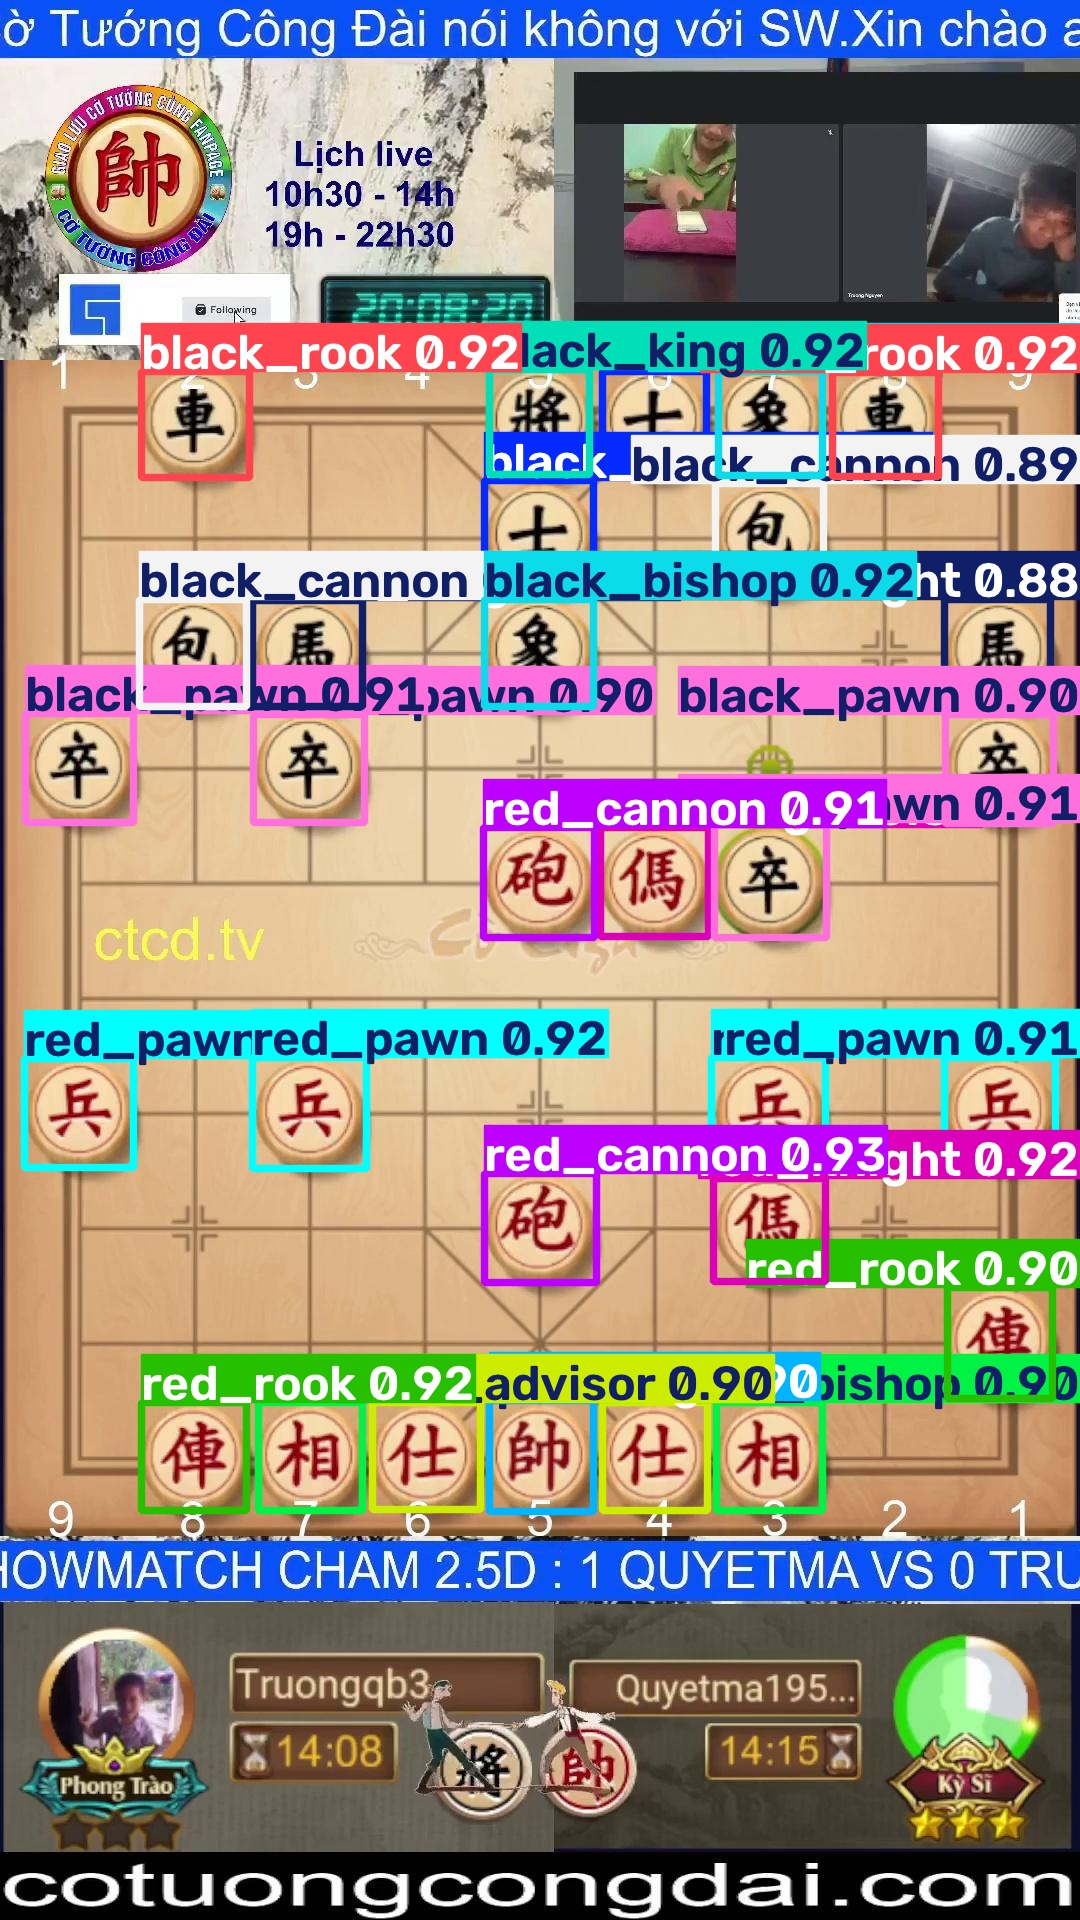

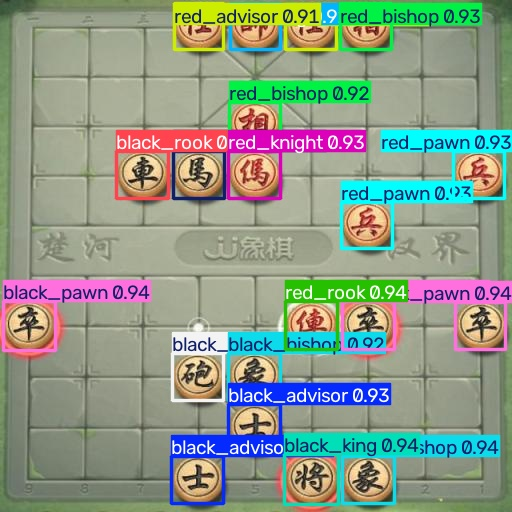

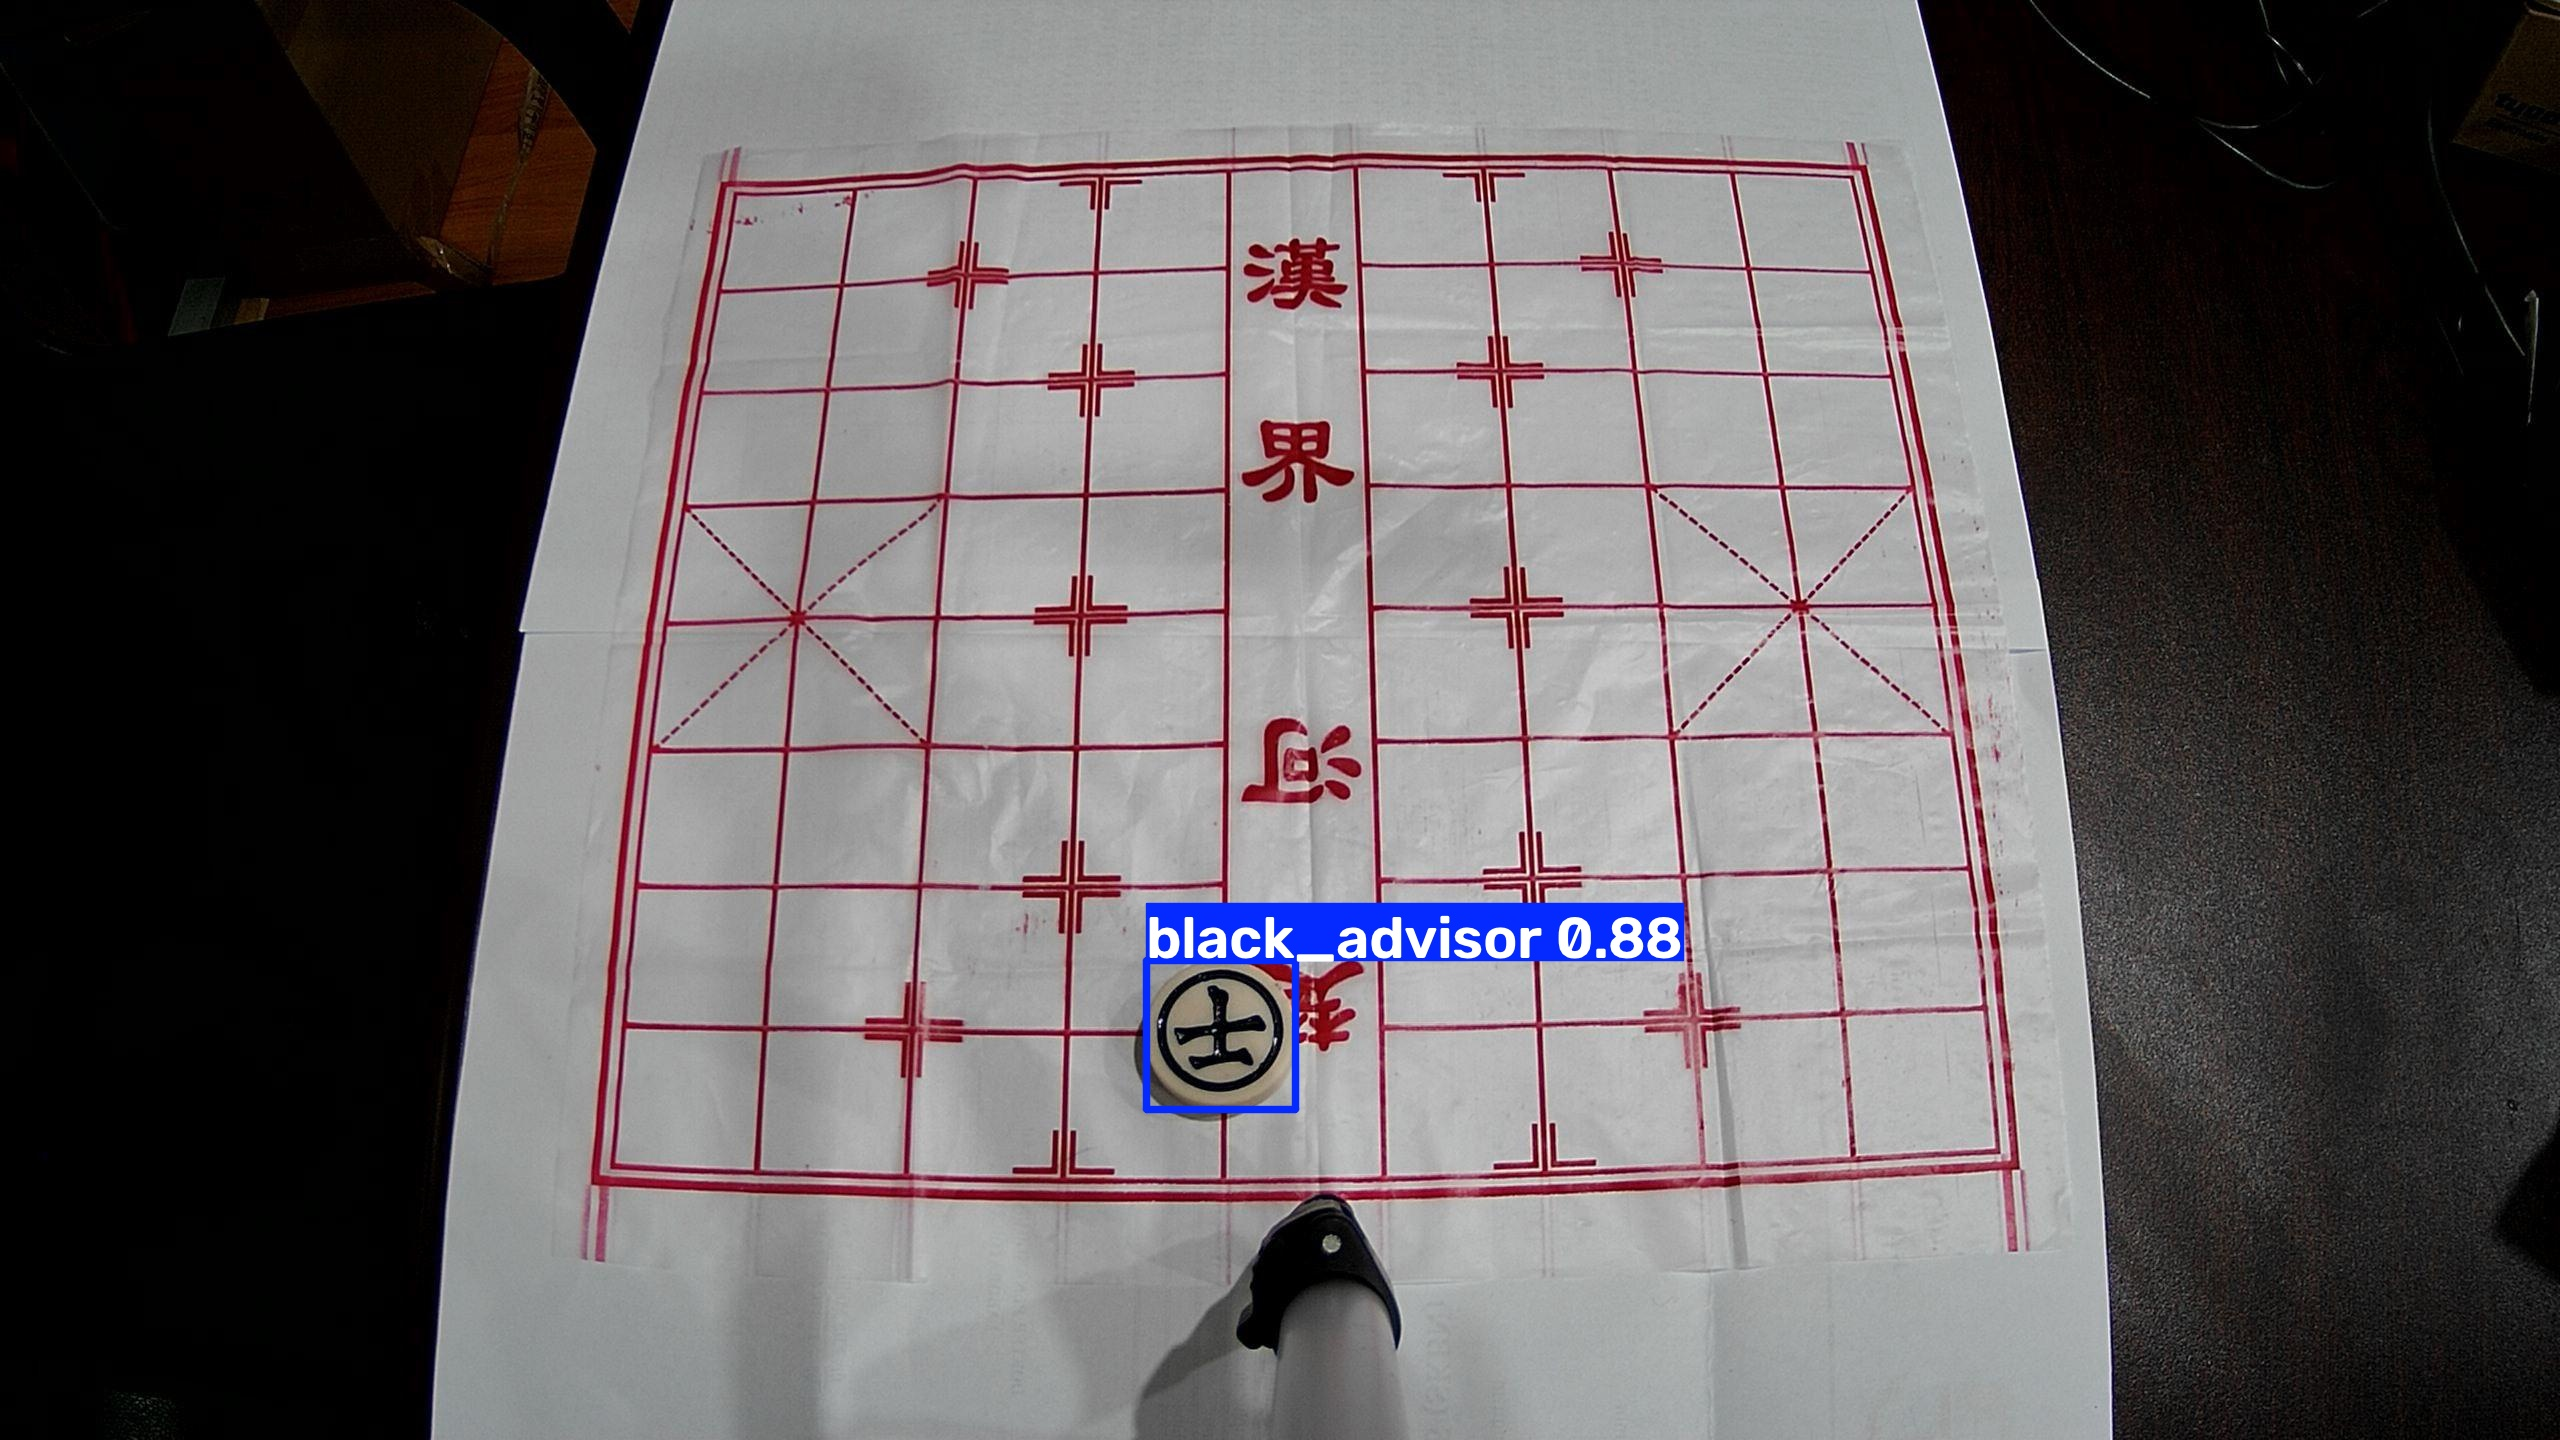

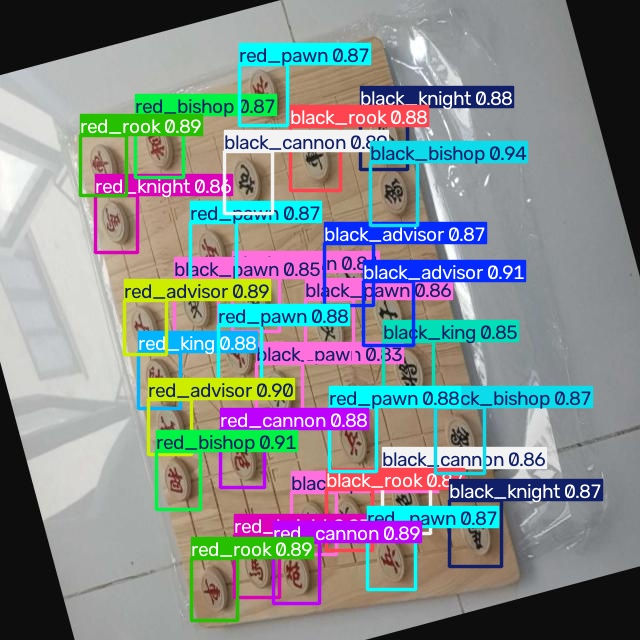

In [18]:
import random
from IPython.display import Image, display

samples = random.sample(glob.glob(f'{MERGED}/test/images/*'), 4)
# conf=0.5: chỉ giữ dự đoán có độ tin cậy >= 50%
preds = best.predict(samples, imgsz=IMGSZ, conf=0.5, save=True,
                     project=PROJECT, name=f'{NAME}_pred', exist_ok=True)

for r in preds:
    display(Image(filename=os.path.join(r.save_dir, os.path.basename(r.path))))

### 🔍 Kiểm tra chi tiết với một ảnh test bất kỳ: nhãn thật vs dự đoán
Chọn một ảnh test, đối chiếu **từng quân**:
🟩 **TP** đúng lớp và đúng vị trí (IoU ≥ 0.5) · 🟥 **FP** báo thừa/sai lớp · 🟧 **FN** bỏ sót (khung đứt nét).
Biểu đồ bên phải là **độ tin cậy** của các dự đoán trên ~200 ảnh test: phần lớn dồn sát 1.0 nghĩa là mô hình rất "chắc chắn", ngưỡng 0.5 hầu như không loại nhầm dự đoán đúng.

> Đặt `TEST_SEED` là một số nguyên để cố định ảnh khi trình bày.

In [ ]:
import matplotlib.patches as mpatches
from collections import Counter

TEST_SEED = None
CONF = 0.5
SHORT = lambda n: n.replace('black_', 'B_').replace('red_', 'R_')

def iou_xyxy(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def match_boxes(gt_xyxy, gt_cls, pr_xyxy, pr_cls, pr_conf, thr=0.5):
    # Ghép tham lam theo confidence giảm dần, chỉ ghép cùng lớp với IoU >= thr
    used, tp = set(), []
    for i in np.argsort(-np.asarray(pr_conf)):
        bj, bv = -1, thr
        for j in range(len(gt_xyxy)):
            if j not in used and gt_cls[j] == pr_cls[i]:
                v = iou_xyxy(pr_xyxy[i], gt_xyxy[j])
                if v >= bv:
                    bj, bv = j, v
        if bj >= 0:
            used.add(bj); tp.append(i)
    return tp, [i for i in range(len(pr_xyxy)) if i not in tp], [j for j in range(len(gt_xyxy)) if j not in used]

def read_gt(img_path, W, H):
    stem = os.path.splitext(os.path.basename(img_path))[0]
    rows = [l.split() for l in open(f'{MERGED}/test/labels/{stem}.txt') if l.strip()]
    xyxy = [((float(x) - float(w) / 2) * W, (float(y) - float(h) / 2) * H,
             (float(x) + float(w) / 2) * W, (float(y) + float(h) / 2) * H) for _, x, y, w, h in rows]
    return xyxy, [int(r[0]) for r in rows]

test_imgs = sorted(glob.glob(f'{MERGED}/test/images/*'))
img_path = test_imgs[random.Random(TEST_SEED).randrange(len(test_imgs))]
img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
gt_xyxy, gt_cls = read_gt(img_path, W, H)
r = best.predict(img_path, imgsz=IMGSZ, conf=CONF, verbose=False)[0]
pr_xyxy, pr_cls, pr_conf = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy()
tp, fp, fn = match_boxes(gt_xyxy, gt_cls, pr_xyxy, pr_cls, pr_conf)

# Độ tin cậy trên nhiều ảnh test (lấy mẫu 200 ảnh cho nhanh)
all_conf = []
for rr in best.predict(random.Random(0).sample(test_imgs, min(200, len(test_imgs))), imgsz=IMGSZ,
                       conf=0.05, verbose=False, stream=True):
    all_conf += rr.boxes.conf.cpu().tolist()

fig = plt.figure(figsize=(22, 7.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.7])
a0, a1, a2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
a0.imshow(img); a0.axis('off'); a0.set_title(f'Nhãn thật: {len(gt_xyxy)} quân\n{os.path.basename(img_path)[:60]}', fontsize=10)
for (x0, y0, x1, y1), c in zip(gt_xyxy, gt_cls):
    col = '#FF3B30' if names[c].startswith('red') else '#1E90FF'
    a0.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=1.8))
    a0.text(x0, y0 - 2, SHORT(names[c]), fontsize=7, color='white', bbox=dict(fc=col, ec='none', pad=1))
a1.imshow(img); a1.axis('off')
for i, (x0, y0, x1, y1) in enumerate(pr_xyxy):
    col = '#2ECC71' if i in tp else '#E74C3C'
    a1.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=2))
    a1.text(x0, y0 - 2, f'{SHORT(names[pr_cls[i]])} {pr_conf[i]:.2f}', fontsize=7, color='white',
            bbox=dict(fc=col, ec='none', pad=1))
for j in fn:
    x0, y0, x1, y1 = gt_xyxy[j]
    a1.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='#F39C12', lw=2, ls='--'))
a1.set_title(f'Dự đoán (conf ≥ {CONF}): TP={len(tp)}  FP={len(fp)}  FN={len(fn)}  ·  {r.speed["inference"]:.1f} ms')
a1.legend(handles=[mpatches.Patch(color='#2ECC71', label='TP'), mpatches.Patch(color='#E74C3C', label='FP'),
                   mpatches.Patch(color='#F39C12', label='FN')], loc='lower right')
a2.hist(all_conf, bins=40, color='#8172B2'); a2.axvline(CONF, color='#C44E52', ls='--')
a2.text(CONF + 0.01, a2.get_ylim()[1] * 0.9, f'ngưỡng {CONF}', color='#C44E52')
a2.set_xlabel('Độ tin cậy (confidence)'); a2.set_ylabel('Số dự đoán'); a2.set_yscale('log')
a2.set_title(f'Phân bố độ tin cậy ({len(all_conf):,} dự đoán)')
plt.tight_layout(); plt.show()
print(f'Ảnh này: precision={len(tp) / max(1, len(tp) + len(fp)):.3f} | recall={len(tp) / max(1, len(gt_xyxy)):.3f}')
print(f'Tỷ lệ dự đoán có conf ≥ 0.9: {(np.array(all_conf) >= 0.9).mean() * 100:.1f}%')

---
# 7. So sánh mô hình giai đoạn 1 và giai đoạn 2 khi quân cờ bị xoay

## So sánh model cũ và mới trên tập test **đã xoay**
Tạo thêm 3 bản của tập test, xoay 90°, 180°, 270° (nhãn được xoay chính xác theo). Đánh giá cả model cũ (`degrees=10`) và model mới (`degrees=180`) trên 4 tập (0°, 90°, 180°, 270°).

Bảng này cho thấy model mới **không bị giảm độ chính xác khi quân xoay**, dùng để đưa vào báo cáo giải thích lý do train lại.

Cách xoay nhãn YOLO (toạ độ chuẩn hoá) theo chiều kim đồng hồ:

| Góc | $(x, y, w, h)$ mới |
|---|---|
| 90° | $(1-y,\; x,\; h,\; w)$ |
| 180° | $(1-x,\; 1-y,\; w,\; h)$ |
| 270° | $(y,\; 1-x,\; h,\; w)$ |

Xoay đúng bội số 90° thì box vẫn khít tuyệt đối, nên đây là phép thử công bằng.

In [19]:
import yaml, pandas as pd
import cv2

ROT = {90: cv2.ROTATE_90_CLOCKWISE, 180: cv2.ROTATE_180, 270: cv2.ROTATE_90_COUNTERCLOCKWISE}

def rot_label(x, y, w, h, deg):
    # toạ độ YOLO chuẩn hoá, xoay theo chiều kim đồng hồ
    if deg == 90:
        return 1 - y, x, h, w
    if deg == 180:
        return 1 - x, 1 - y, w, h
    return y, 1 - x, h, w          # 270

# Tạo 3 bản tập test đã xoay (ảnh + nhãn), mỗi bản có data.yaml riêng
ROT_ROOT = '/content/test_rot'
yamls = {0: DATA}
for deg, code in ROT.items():
    root = f'{ROT_ROOT}/r{deg}'
    if not os.path.isdir(f'{root}/images'):
        os.makedirs(f'{root}/images'); os.makedirs(f'{root}/labels')
        for f in os.listdir(f'{MERGED}/test/images'):
            img = cv2.imread(f'{MERGED}/test/images/{f}')
            if img is None:
                continue
            cv2.imwrite(f'{root}/images/{f}', cv2.rotate(img, code))
            stem = os.path.splitext(f)[0]
            out = []
            for line in open(f'{MERGED}/test/labels/{stem}.txt'):
                p = line.split()
                if len(p) == 5:
                    x, y, w, h = rot_label(*map(float, p[1:]), deg)
                    out.append(f'{p[0]} {x:.6f} {y:.6f} {w:.6f} {h:.6f}')
            open(f'{root}/labels/{stem}.txt', 'w').write('\n'.join(out) + '\n')
    yp = f'{root}/data.yaml'
    with open(yp, 'w') as fh:
        yaml.safe_dump({'path': root, 'train': 'images', 'val': 'images', 'test': 'images',
                        'nc': 14, 'names': list(best.names.values())}, fh, sort_keys=False)
    yamls[deg] = yp

# Đánh giá 2 mô hình x 4 góc = 8 lần val
rows = []
for tag, w in [('cũ (degrees=10)', OLD_BEST), ('mới (degrees=180)', f'{PROJECT}/{NAME}/weights/best.pt')]:
    m = YOLO(w)
    row = {'model': tag}
    for deg, yp in yamls.items():
        r = m.val(data=yp, split='test', imgsz=IMGSZ, verbose=False, plots=False,
                  project=PROJECT, name=f'{NAME}_cmp', exist_ok=True)
        row[f'mAP50 {deg}°'] = round(r.box.map50, 4)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,210 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2717.1±1632.4 MB/s, size: 108.8 KB)
val: Scanning /content/merged/test/labels.cache... 664 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 664/664 214.2Mit/s 0.0s
val: /content/merged/test/images/scara__BanCo_2_Giua_Tran_55_jpg.rf.92a702c940b241579afb901d90a6a697.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_12_jpg.rf.0fb512aad154bd15e2c026bee64cdfb3.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_12_jpg.rf.9a47b01dbbee0c3d56f1936bd25eafde.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_12_jpg.rf.a3b47bfbed13087764d8baa6bbf8e07d.jpg: 1 duplicate labels removed
val: /content/merged/test/images/scara__BanCo_4_Tung_Quan_Co_50_jpg.rf.683c

### 📊 Biểu đồ: độ bền của mô hình theo góc xoay
**Nhận xét:**
- Mô hình **cũ** tụt mạnh ở 90° và 270° (0.96 → **0.76**), nhưng ở 180° chỉ còn 0.90. Có thể giải thích: trong ảnh bàn cờ đầy đủ, quân của hai bên vốn quay ngược nhau, nên dữ liệu gốc đã có sẵn chữ lộn ngược 180°, nhưng gần như không có chữ nằm ngang 90°.
- Mô hình **mới** giữ **0.968 ở mọi góc** và còn nhỉnh hơn mô hình cũ ở góc 0° → việc thêm xoay **không làm giảm** độ chính xác ban đầu.

In [ ]:
cmp_df = pd.DataFrame(rows).set_index('model')
angles = [c.split()[-1] for c in cmp_df.columns]
x = np.arange(len(angles)); wbar = 0.38

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={'width_ratios': [1.4, 1]})
for k, (tag, color) in enumerate(zip(cmp_df.index, ['#4C72B0', '#C44E52'])):
    vals = cmp_df.loc[tag].values
    bars = axes[0].bar(x + (k - 0.5) * wbar, vals, wbar, color=color, label=tag)
    for bx, v in zip(bars, vals):
        axes[0].text(bx.get_x() + bx.get_width() / 2, v + 0.005, f'{v:.3f}', ha='center', fontsize=10)
axes[0].axhline(0.95, color='gray', ls=':', lw=1.5); axes[0].text(-0.45, 0.955, 'mục tiêu 0.95', color='gray')
axes[0].set_xticks(x); axes[0].set_xticklabels([f'xoay {a}' for a in angles])
axes[0].set_ylim(0.6, 1.02); axes[0].set_ylabel('mAP@0.5 trên tập test'); axes[0].legend(loc='lower center')
axes[0].set_title('mAP@0.5 khi xoay toàn bộ ảnh test')

# Biểu đồ cực: nhìn trực quan "vòng tròn" độ chính xác theo góc
ax = plt.subplot(1, 2, 2, projection='polar'); axes[1].remove()
theta = np.deg2rad([0, 90, 180, 270, 360])
for tag, color in zip(cmp_df.index, ['#4C72B0', '#C44E52']):
    v = list(cmp_df.loc[tag].values); v.append(v[0])
    ax.plot(theta, v, 'o-', color=color, lw=2, label=tag); ax.fill(theta, v, color=color, alpha=0.1)
ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
ax.set_xticks(np.deg2rad([0, 90, 180, 270])); ax.set_xticklabels(['0°', '90°', '180°', '270°'])
ax.set_ylim(0.6, 1.0); ax.set_title('Độ chính xác theo hướng quân', pad=18)
ax.legend(loc='lower right', bbox_to_anchor=(1.35, -0.1), fontsize=9)
plt.tight_layout(); plt.show()

### 🖼 Minh hoạ trực quan: cùng một ảnh test, xoay 4 góc, hai mô hình
Hàng trên là mô hình **cũ**, hàng dưới là mô hình **mới**. Tiêu đề mỗi ô ghi *số quân phát hiện được / số quân thật*.

In [ ]:
ROT_SEED = 0       # đổi số để chọn ảnh khác
# Ưu tiên ảnh có nhiều quân để thấy rõ khác biệt
cand = [p for p in test_imgs
        if sum(1 for _ in open(f'{MERGED}/test/labels/{os.path.splitext(os.path.basename(p))[0]}.txt')) >= 10]
pick = random.Random(ROT_SEED).choice(cand or test_imgs)
base_img = cv2.imread(pick)
n_gt = sum(1 for l in open(f'{MERGED}/test/labels/{os.path.splitext(os.path.basename(pick))[0]}.txt') if l.strip())

models_cmp = [('Cũ (degrees=10)', YOLO(OLD_BEST)), ('Mới (degrees=180)', best)]
fig, axes = plt.subplots(2, 4, figsize=(22, 11.5))
for r_i, (tag, m) in enumerate(models_cmp):
    for c_i, deg in enumerate([0, 90, 180, 270]):
        im = base_img if deg == 0 else cv2.rotate(base_img, ROT[deg])
        res_r = m.predict(im, imgsz=IMGSZ, conf=0.5, verbose=False)[0]
        vis = res_r.plot(line_width=2, font_size=10)                 # ảnh BGR đã vẽ box
        ax = axes[r_i][c_i]
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis('off')
        n = len(res_r.boxes)
        ax.set_title(f'{tag} · xoay {deg}° · {n}/{n_gt} quân', fontsize=11,
                     color='#2E7D32' if abs(n - n_gt) <= max(1, n_gt * 0.05) else '#C62828')
fig.suptitle('Mô hình cũ bỏ sót / nhầm nhiều khi xoay 90°, 270° — mô hình mới ổn định ở mọi góc',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

---
# 8. Xuất mô hình để triển khai lên robot

## Xuất mô hình sang ONNX
`best.pt` dùng được ngay với Ultralytics, còn ONNX là định dạng trung gian để chuyển sang TensorRT. Xuất với **`opset=12`** vì TensorRT 8.x trên Jetson Nano (JetPack 4.x) không đọc được opset mới hơn. **Lưu ý:** file TensorRT (`.engine`) phải được tạo trực tiếp trên Jetson của robot, không tạo trên Colab được, vì nó phụ thuộc vào GPU và phiên bản TensorRT của thiết bị.

In [20]:
# opset=12: TensorRT 8.x trên JetPack 4.x không đọc được opset mới hơn
# simplify=True: rút gọn đồ thị ONNX (gộp/bỏ node thừa) -> build TensorRT dễ hơn
onnx_path = best.export(format='onnx', imgsz=IMGSZ, opset=12, simplify=True)
print('Đã xuất:', onnx_path)
print('Các file trong thư mục weights:', os.listdir(f'{PROJECT}/{NAME}/weights'))

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,600,210 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/datn/runs/yolo11n_640_rot/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 18, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 267ms
Prepared 4 packages in 557ms
Installed 4 packages in 34ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 1

### Đầu ra của mô hình ONNX: tensor `(1, 18, 8400)`
- **18** = 4 toạ độ box $(x_c, y_c, w, h)$ + **14** điểm số cho 14 lớp.
- **8 400** = số "ô dự đoán" ở 3 tỉ lệ: $80^2 + 40^2 + 20^2 = 6400 + 1600 + 400$ (stride 8, 16, 32 trên ảnh 640).
- Mô hình **chưa có NMS** bên trong → phía robot phải tự: (1) lấy lớp có điểm cao nhất của mỗi ô, (2) lọc theo ngưỡng confidence, (3) chạy NMS để bỏ box trùng, (4) đổi toạ độ từ ảnh 640 (đã letterbox) về ảnh gốc.

Ô dưới làm đúng 4 bước đó bằng **onnxruntime + NumPy + OpenCV** (giống code sẽ chạy trên robot) và so với kết quả của Ultralytics trên cùng một ảnh, để chắc chắn file ONNX hoạt động đúng trước khi mang sang Jetson. Số quân và lớp phải trùng nhau; toạ độ box có thể lệch vài pixel vì Ultralytics đệm viền tối thiểu (ảnh 640×480 thay vì 640×640) — không ảnh hưởng kết quả.

In [ ]:
import time
try:
    import onnxruntime as ort
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnxruntime'], check=True)
    import onnxruntime as ort

def letterbox(img, size=640):
    # Thu ảnh về size×size giữ tỷ lệ, đệm viền màu 114 (giống Ultralytics)
    h, w = img.shape[:2]; s = min(size / h, size / w)
    nh, nw = round(h * s), round(w * s)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas = np.full((size, size, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    return canvas, s, left, top

def onnx_detect(sess, img_bgr, conf_thr=0.5, iou_thr=0.7, size=640):
    lb, s, left, top = letterbox(img_bgr, size)
    blob = lb[:, :, ::-1].transpose(2, 0, 1)[None].astype(np.float32) / 255.0      # BGR->RGB, HWC->NCHW, 0..1
    out = sess.run(None, {sess.get_inputs()[0].name: blob})[0][0]                  # (18, 8400)
    boxes, scores = out[:4].T, out[4:].T                                            # (8400, 4), (8400, 14)
    cls, conf = scores.argmax(1), scores.max(1)
    keep = conf >= conf_thr
    boxes, cls, conf = boxes[keep], cls[keep], conf[keep]
    xywh_tl = np.c_[boxes[:, 0] - boxes[:, 2] / 2, boxes[:, 1] - boxes[:, 3] / 2, boxes[:, 2], boxes[:, 3]]
    if hasattr(cv2.dnn, 'NMSBoxesBatched'):                                         # NMS theo từng lớp
        idx = cv2.dnn.NMSBoxesBatched(xywh_tl.tolist(), conf.tolist(), cls.tolist(), conf_thr, iou_thr)
    else:
        idx = cv2.dnn.NMSBoxes(xywh_tl.tolist(), conf.tolist(), conf_thr, iou_thr)
    idx = np.array(idx).reshape(-1).astype(int)
    xyxy = np.c_[xywh_tl[:, :2], xywh_tl[:, :2] + xywh_tl[:, 2:]][idx]
    xyxy = (xyxy - [left, top, left, top]) / s                                      # về toạ độ ảnh gốc
    return xyxy, cls[idx], conf[idx]

sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
print('Input :', sess.get_inputs()[0].name, sess.get_inputs()[0].shape)
print('Output:', sess.get_outputs()[0].name, sess.get_outputs()[0].shape)

img_bgr = cv2.imread(pick)
t0 = time.perf_counter(); o_xyxy, o_cls, o_conf = onnx_detect(sess, img_bgr); t_onnx = (time.perf_counter() - t0) * 1000
pt = best.predict(img_bgr, imgsz=IMGSZ, conf=0.5, verbose=False)[0]
p_cls = pt.boxes.cls.cpu().numpy().astype(int)

cmp_cls = pd.DataFrame({'PyTorch (Ultralytics)': Counter(names[c] for c in p_cls),
                        'ONNX (tự giải mã)': Counter(names[c] for c in o_cls)}).fillna(0).astype(int)
print(f'\nSố quân: PyTorch = {len(p_cls)} | ONNX = {len(o_cls)} | ONNX trên CPU Colab: {t_onnx:.0f} ms/ảnh')
display(cmp_cls)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].imshow(cv2.cvtColor(pt.plot(line_width=2), cv2.COLOR_BGR2RGB)); axes[0].set_title(f'PyTorch best.pt: {len(p_cls)} quân')
vis = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
axes[1].imshow(vis)
for (x0, y0, x1, y1), c, cf in zip(o_xyxy, o_cls, o_conf):
    col = '#FF3B30' if names[c].startswith('red') else '#1E90FF'
    axes[1].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=2))
    axes[1].text(x0, y0 - 2, f'{SHORT(names[c])} {cf:.2f}', fontsize=7, color='white', bbox=dict(fc=col, ec='none', pad=1))
axes[1].set_title(f'ONNX best.onnx + NMS tự viết: {len(o_cls)} quân')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## Tải kết quả về máy
Nén thư mục kết quả và tải về, giải nén vào `runs/yolo11n_640_rot/` trong dự án. Bản gốc vẫn còn trên Drive. Các file cần mang sang robot: `weights/best.pt` và `weights/best.onnx`.

In [21]:
from google.colab import files

# Nén cả thư mục run (weights, results.csv, biểu đồ) để tải về máy
shutil.make_archive(f'/content/{NAME}', 'zip', f'{PROJECT}/{NAME}')
files.download(f'/content/{NAME}.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Tổng kết

| Hạng mục | Nội dung |
|---|---|
| Mô hình | **YOLO11n** — 2.6M tham số, 6.5 GFLOPs, 5.5 MB |
| Phương pháp | Transfer learning 2 giai đoạn: COCO → quân cờ (`degrees=10`) → fine-tune quân xoay (`degrees=180`) |
| Tham số then chốt | `imgsz=640`, `batch=32`, AdamW `lr0=0.001`, 60 epoch, **không lật ảnh**, xoay ±180° |
| Thời gian train GĐ2 | 1.7 giờ trên Tesla T4 |
| Kết quả test | **mAP@0.5 = 0.968**, mAP@0.5:0.95 = 0.823, P = 0.986, R = 0.961 |
| Khi xoay 90/180/270° | mô hình cũ 0.76 / 0.90 / 0.77 → mô hình mới **0.968 / 0.968 / 0.968** |
| Lớp yếu nhất | `black_cannon` (0.904) — hướng cải thiện: bổ sung ảnh của lớp này |
| Triển khai | `best.onnx` (opset 12) → `trtexec --fp16` build TensorRT engine **trên chính Jetson Nano** |

**Hướng phát triển:**
1. Thu thập ảnh từ **chính camera của robot JetMax** (thư mục `own_images/`) và fine-tune thêm để sát điều kiện thực tế.
2. Bổ sung dữ liệu cho `black_cannon` và các lớp có recall thấp.
3. Đo tốc độ thực tế của engine TensorRT FP16 trên Jetson Nano.